In [1]:
%pip install matplotlib seaborn



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
# ==========================================
# CELL 1: Environment Setup & Data Loading
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the generated dataset
df = pd.read_csv("../data/processed_dataset_10.csv")

# Confirm data schema and scaling
display(df.head())
df.info()

,Hypotension,Sex,Age,Dialyzer,Dialysate_Bath,Dry_Weight,Pre_Weight,Weight_Gain,Dialysate_Temperature,Blood_Flow,Dialysate_Flow,Dialysate_Conductivity,Arterial_Pressure,Venous_Pressure,Transmembrane_Pressure,Systolic_BP,Diastolic_BP,Pulse,Patient_Temperature
0,0,1,0.709677,0.25,0.0,0.485075,0.491228,0.416378,0.333333,0.827586,0.973171,0.928571,0.441860,0.476190,0.567568,0.176471,0.118280,0.375000,0.962466
1,0,1,0.709677,0.25,0.0,0.485075,0.491228,0.416378,0.333333,0.827586,0.975610,0.285714,0.372093,0.571429,0.675676,0.169118,0.139785,0.388889,0.983914
2,0,1,0.709677,0.25,0.0,0.485075,0.508772,0.659264,0.333333,0.827586,0.982927,0.428571,0.372093,0.547619,0.864865,0.080882,0.064516,0.555556,0.983914
3,0,1,0.709677,0.25,0.0,0.485075,0.502924,0.451076,0.333333,0.827586,0.000000,0.357143,0.372093,0.523810,0.756757,0.183824,0.118280,0.375000,0.983914
4,0,1,0.709677,0.25,0.0,0.485075,0.500000,0.451076,0.333333,0.482759,0.967073,0.285714,0.651163,0.333333,0.729730,0.095588,0.086022,0.375000,0.986595


<class 'pandas.DataFrame'>
RangeIndex: 13637 entries, 0 to 13636
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Hypotension             13637 non-null  int64  
 1   Sex                     13637 non-null  int64  
 2   Age                     13637 non-null  float64
 3   Dialyzer                13637 non-null  float64
 4   Dialysate_Bath          13637 non-null  float64
 5   Dry_Weight              13637 non-null  float64
 6   Pre_Weight              13637 non-null  float64
 7   Weight_Gain             13637 non-null  float64
 8   Dialysate_Temperature   13637 non-null  float64
 9   Blood_Flow              13637 non-null  float64
 10  Dialysate_Flow          13637 non-null  float64
 11  Dialysate_Conductivity  13637 non-null  float64
 12  Arterial_Pressure       13637 non-null  float64
 13  Venous_Pressure         13637 non-null  float64
 14  Transmembrane_Pressure  13637 non-null  float64
 

Class Imbalance Breakdown (%):
Hypotension
0    79.606952
1    20.393048
Name: proportion, dtype: float64


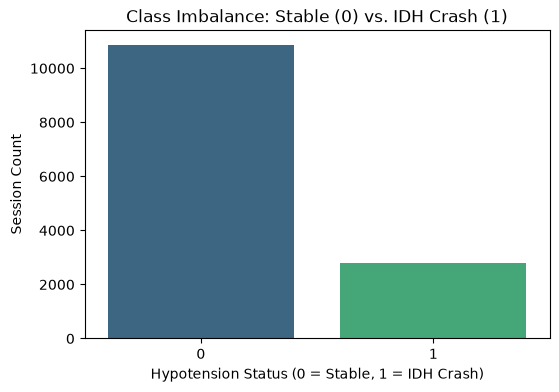

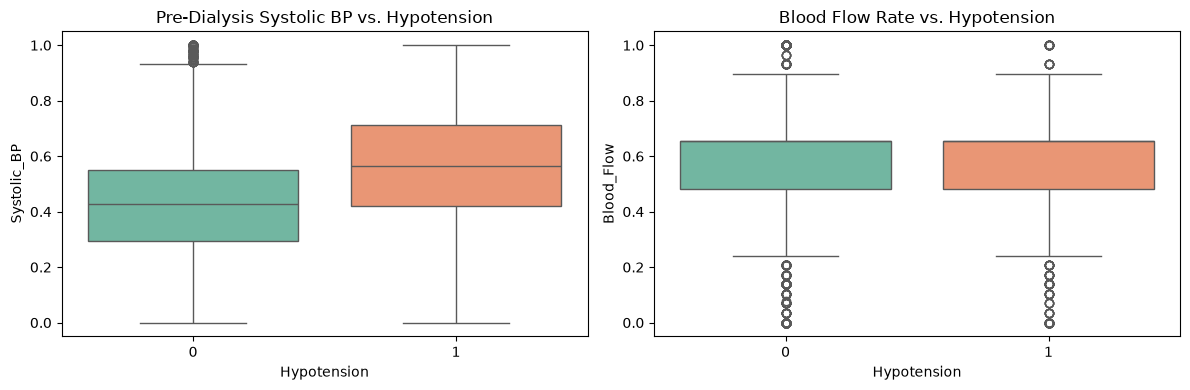

In [7]:
# ==========================================
# CELL 2: Bivariate EDA & Target Class Imbalance Analysis
# ==========================================
# 1. Exact class imbalance breakdown
print("Class Imbalance Breakdown (%):")
print(df['Hypotension'].value_counts(normalize=True) * 100)

# 2. Visualize Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Hypotension', hue='Hypotension',
              palette='viridis', legend=False)
plt.title("Class Imbalance: Stable (0) vs. IDH Crash (1)")
plt.xlabel("Hypotension Status (0 = Stable, 1 = IDH Crash)")
plt.ylabel("Session Count")
plt.show()

# 3. Compare Key Clinical Variables across Target Groups
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='Hypotension', y='Systolic_BP',
            hue='Hypotension', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title("Pre-Dialysis Systolic BP vs. Hypotension")

sns.boxplot(data=df, x='Hypotension', y='Blood_Flow',
            hue='Hypotension', ax=axes[1], palette='Set2', legend=False)
axes[1].set_title("Blood Flow Rate vs. Hypotension")

plt.tight_layout()
plt.show()

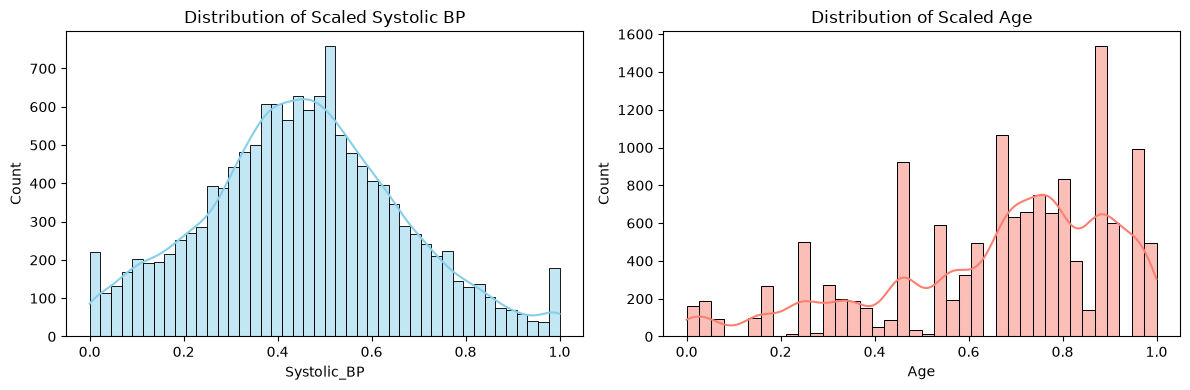

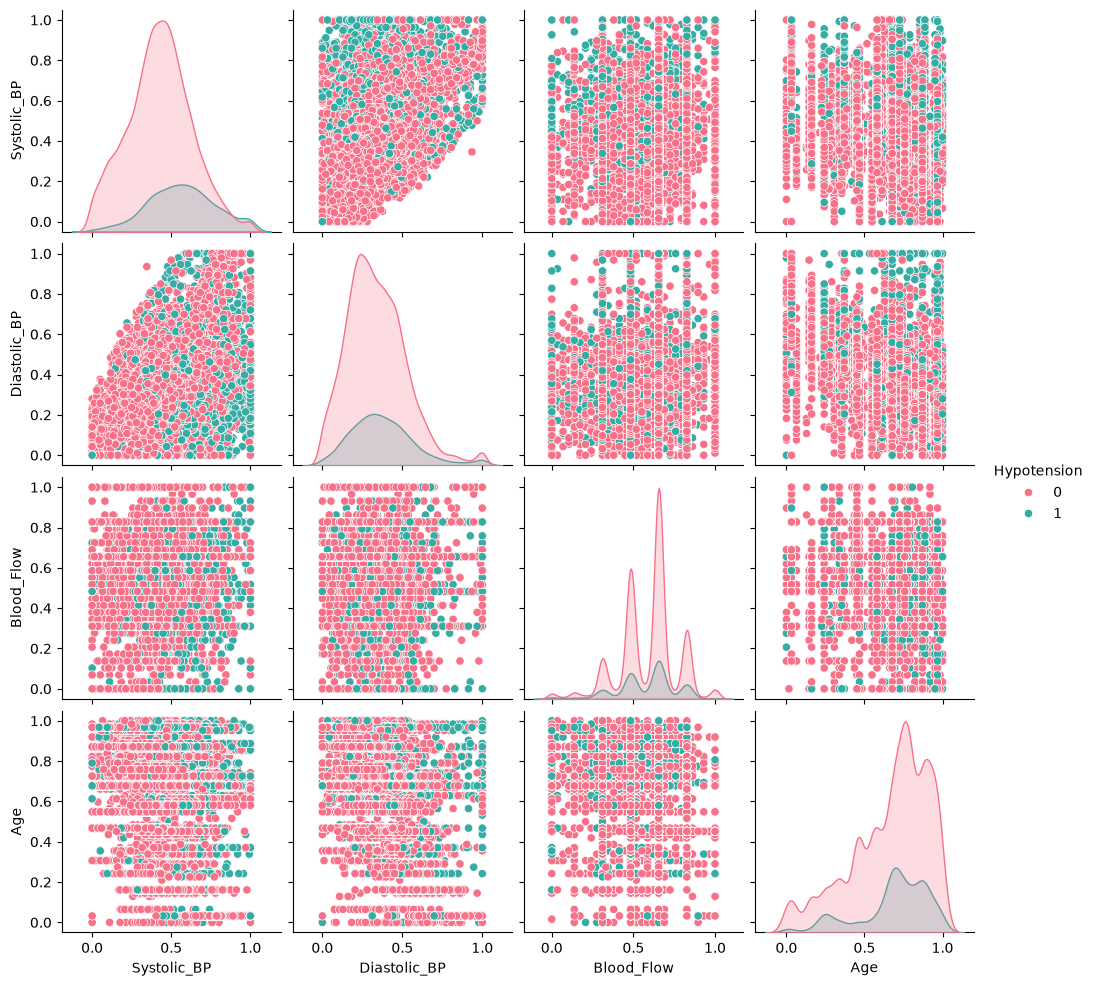

In [8]:
# ==========================================
# CELL 3: Multivariate EDA & Feature Distributions
# ==========================================
# 1. Feature Distributions (Checking spread & shape after winsorization)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['Systolic_BP'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribution of Scaled Systolic BP")

sns.histplot(df['Age'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title("Distribution of Scaled Age")

plt.tight_layout()
plt.show()

# 2. Pairplot of critical features colored by Hypotension
key_features = ['Systolic_BP', 'Diastolic_BP',
                'Blood_Flow', 'Age', 'Hypotension']
sns.pairplot(df[key_features], hue='Hypotension',
             palette='husl', diag_kind='kde')
plt.show()

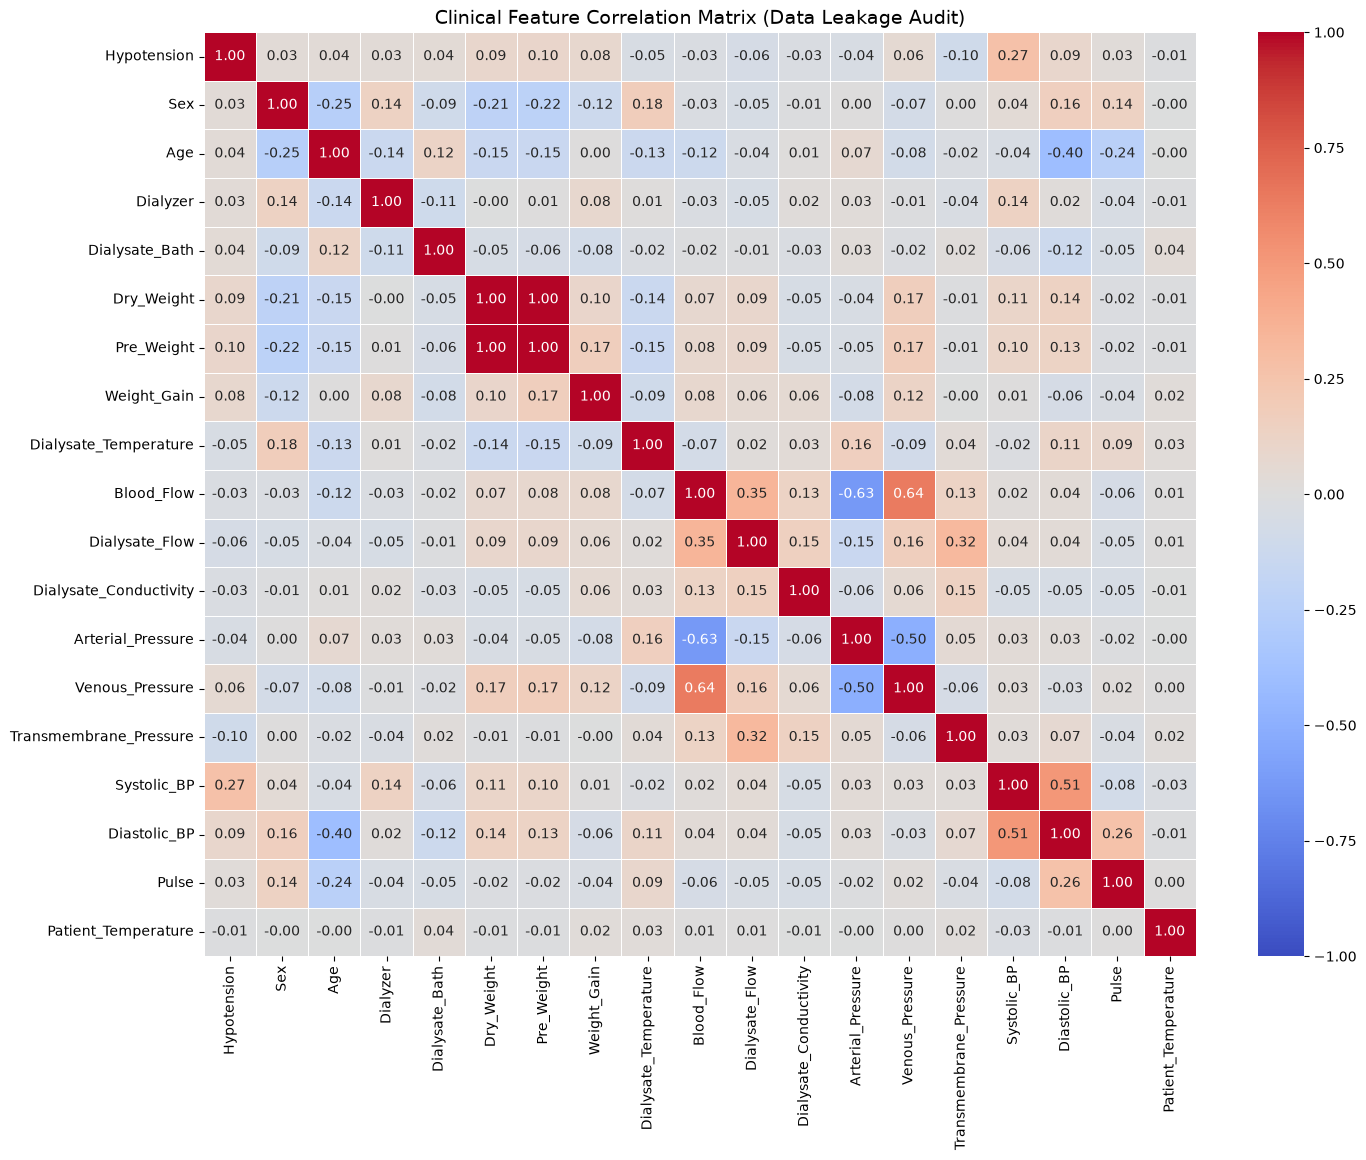


Feature Correlations with Target (Hypotension):
Hypotension               1.000000
Systolic_BP               0.270897
Pre_Weight                0.100384
Dry_Weight                0.092367
Diastolic_BP              0.086846
Weight_Gain               0.078792
Venous_Pressure           0.061532
Dialysate_Bath            0.040772
Age                       0.037642
Dialyzer                  0.033134
Sex                       0.032604
Pulse                     0.029930
Patient_Temperature      -0.012489
Blood_Flow               -0.025109
Dialysate_Conductivity   -0.027180
Arterial_Pressure        -0.043373
Dialysate_Temperature    -0.045935
Dialysate_Flow           -0.059391
Transmembrane_Pressure   -0.098806
Name: Hypotension, dtype: float64


In [9]:
# ==========================================
# CELL 4: Correlation Matrix & Data Leakage Audit
# ==========================================
# 1. Compute and plot feature correlation heatmap
plt.figure(figsize=(16, 12))
corr_matrix = df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Clinical Feature Correlation Matrix (Data Leakage Audit)", fontsize=14)
plt.show()

# 2. Inspect target correlations sorted by magnitude
print("\nFeature Correlations with Target (Hypotension):")
print(corr_matrix['Hypotension'].sort_values(ascending=False))